# EDA – Road Traffic Accidents in Germany 2025 (Unfallatlas)

## Setup
Import the libraries and load the dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

unfall_raw = pd.read_csv("data/Unfallorte_2025.csv", sep=";")
unfall_raw.head()

/var/folders/rv/3zstxldn3b93ft9yj1vjb4j40000gn/T/ipykernel_7188/2965695596.py:4: DtypeWarning: Columns (0: UIDENTSTLAE) have mixed types. Specify dtype option on import or set low_memory=False.
  unfall_raw = pd.read_csv("data/Unfallorte_2025.csv", sep=";")


,UIDENTSTLAE,ULAND,UREGBEZ,UKREIS,UGEMEINDE,UJAHR,UMONAT,USTUNDE,UWOCHENTAG,UKATEGORIE,...,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstige,LINREFX,LINREFY,XGCSWGS84,YGCSWGS84,PLST
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,1,0,0,0,0,"578658,645899999886751","5975441,506100000813603","10,197759334000068","53,921402971000077",1
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,0,"577747,035899999551475","5933250,982200000435114","10,173275287000024","53,542398901000070",1
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,1,0,0,0,0,"543500,281399999745190","5955819,687799999490380","9,659670060000053","53,749196565000034",1
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,1,0,0,0,"601362,065600000321865","6003468,873199999332428","10,552708229000075","54,169272189000083",1
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,0,"565151,556099999696016","6035315,988099999725819","10,005090446000054","54,461325762000058",1


In [2]:
unfall_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 25 columns):
 #   Column              Non-Null Count   Dtype 
---  ------              --------------   ----- 
 0   UIDENTSTLAE         273007 non-null  object
 1   ULAND               273007 non-null  int64 
 2   UREGBEZ             273007 non-null  int64 
 3   UKREIS              273007 non-null  int64 
 4   UGEMEINDE           273007 non-null  int64 
 5   UJAHR               273007 non-null  int64 
 6   UMONAT              273007 non-null  int64 
 7   USTUNDE             273007 non-null  int64 
 8   UWOCHENTAG          273007 non-null  int64 
 9   UKATEGORIE          273007 non-null  int64 
 10  UART                273007 non-null  int64 
 11  UTYP1               273007 non-null  int64 
 12  ULICHTVERH          273007 non-null  int64 
 13  IstStrassenzustand  273007 non-null  int64 
 14  IstRad              273007 non-null  int64 
 15  IstPKW              273007 non-null  int64 
 16  IstFuss      

### Data types
- The dataset has **273,007 rows** and **25 columns**.
- There are **no missing values** (all columns have 273,007 non-null entries).
- 20 columns are **integers**, 1 is an **object** (UIDENTSTLAE), and 4 are **text** (LINREFX, LINREFY, XGCSWGS84, YGCSWGS84).

In [3]:
unfall_raw.columns

Index(['UIDENTSTLAE', 'ULAND', 'UREGBEZ', 'UKREIS', 'UGEMEINDE', 'UJAHR',
       'UMONAT', 'USTUNDE', 'UWOCHENTAG', 'UKATEGORIE', 'UART', 'UTYP1',
       'ULICHTVERH', 'IstStrassenzustand', 'IstRad', 'IstPKW', 'IstFuss',
       'IstKrad', 'IstGkfz', 'IstSonstige', 'LINREFX', 'LINREFY', 'XGCSWGS84',
       'YGCSWGS84', 'PLST'],
      dtype='str')

### Column descriptions
Source: official Unfallatlas data record description.

| Column | Description | Values |
|---|---|---|
| UIDENTSTLAE | Serial number (ID) of the accident | Unique identifier |
| ULAND | Federal state | 1 = Schleswig-Holstein, 2 = Hamburg, 3 = Niedersachsen, 4 = Bremen, 5 = Nordrhein-Westfalen, 6 = Hessen, 7 = Rheinland-Pfalz, 8 = Baden-Württemberg, 9 = Bayern, 10 = Saarland, 11 = Berlin, 12 = Brandenburg, 13 = Mecklenburg-Vorpommern, 14 = Sachsen, 15 = Sachsen-Anhalt, 16 = Thüringen |
| UREGBEZ | Administrative region (from the official municipality code) | Code |
| UKREIS | Administrative district | Code |
| UGEMEINDE | Municipality | Code |
| UJAHR | Year of the accident | 2025 |
| UMONAT | Month of the accident | 1–12 |
| USTUNDE | Hour of the accident | 0–23 |
| UWOCHENTAG | Day of the week | 1 = Sunday, 2 = Monday, 3 = Tuesday, 4 = Wednesday, 5 = Thursday, 6 = Friday, 7 = Saturday |
| UKATEGORIE | Accident category (most serious outcome) | 1 = persons killed, 2 = seriously injured, 3 = slightly injured |
| UART | Kind of accident | 1 = collision with a vehicle starting, stopping or stationary, 2 = with a vehicle moving ahead or waiting, 3 = with a vehicle moving laterally in the same direction, 4 = with an oncoming vehicle, 5 = with a vehicle turning into or crossing a road, 6 = between vehicle and pedestrian, 7 = with an obstacle in the carriageway, 8 = leaving the carriageway to the right, 9 = leaving the carriageway to the left, 0 = other kind |
| UTYP1 | Type of accident | 1 = driving accident, 2 = turning off the road, 3 = turning into a road or crossing it, 4 = crossing the road, 5 = involving stationary traffic, 6 = between vehicles moving along the carriageway, 7 = other |
| ULICHTVERH | Light conditions | 0 = daylight, 1 = twilight, 2 = darkness |
| IstStrassenzustand | Road surface condition | 0 = dry, 1 = wet/damp/slippery, 2 = slippery (winter) |
| IstRad | At least one bicycle involved | 0 = no, 1 = yes |
| IstPKW | At least one passenger car involved | 0 = no, 1 = yes |
| IstFuss | At least one pedestrian involved | 0 = no, 1 = yes |
| IstKrad | At least one motorcycle involved | 0 = no, 1 = yes |
| IstGkfz | At least one goods vehicle involved (over 3.5 t, semi-trailer, tractor, dangerous goods) | 0 = no, 1 = yes |
| IstSonstige | At least one other means of transport involved (e.g. bus, tram) | 0 = no, 1 = yes |
| LINREFX | X-coordinate of the accident location (UTM, EPSG:25832) | Metres |
| LINREFY | Y-coordinate of the accident location (UTM, EPSG:25832) | Metres |
| XGCSWGS84 | Longitude of the accident location (WGS84) | Decimal degrees |
| YGCSWGS84 | Latitude of the accident location (WGS84) | Decimal degrees |
| PLST | Plausibility check level of the location | 1 = regular check, 2 = advanced check for bicycle accidents |

### Renaming columns
The original German abbreviations are renamed to clear English names for easier reading.

In [4]:
acc = unfall_raw.rename(columns={
    "UIDENTSTLAE": "accident_id",
    "ULAND": "state",
    "UREGBEZ": "region",
    "UKREIS": "district",
    "UGEMEINDE": "municipality",
    "UJAHR": "year",
    "UMONAT": "month",
    "USTUNDE": "hour",
    "UWOCHENTAG": "weekday",
    "UKATEGORIE": "severity",
    "UART": "accident_kind",
    "UTYP1": "accident_type",
    "ULICHTVERH": "light",
    "IstStrassenzustand": "road_condition",
    "IstRad": "bicycle",
    "IstPKW": "car",
    "IstFuss": "pedestrian",
    "IstKrad": "motorcycle",
    "IstGkfz": "truck",
    "IstSonstige": "other_vehicle",
    "LINREFX": "utm_x",
    "LINREFY": "utm_y",
    "XGCSWGS84": "longitude",
    "YGCSWGS84": "latitude",
    "PLST": "location_check",
})
acc["severe"] = (acc["severity"] <= 2).astype(int)
acc.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,pedestrian,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,0,0,0,0,"578658,645899999886751","5975441,506100000813603","10,197759334000068","53,921402971000077",1,0
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,0,"577747,035899999551475","5933250,982200000435114","10,173275287000024","53,542398901000070",1,0
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,0,0,0,0,"543500,281399999745190","5955819,687799999490380","9,659670060000053","53,749196565000034",1,0
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,1,0,0,0,"601362,065600000321865","6003468,873199999332428","10,552708229000075","54,169272189000083",1,0
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,0,"565151,556099999696016","6035315,988099999725819","10,005090446000054","54,461325762000058",1,0


In [5]:
acc.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 26 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   accident_id     273007 non-null  object
 1   state           273007 non-null  int64 
 2   region          273007 non-null  int64 
 3   district        273007 non-null  int64 
 4   municipality    273007 non-null  int64 
 5   year            273007 non-null  int64 
 6   month           273007 non-null  int64 
 7   hour            273007 non-null  int64 
 8   weekday         273007 non-null  int64 
 9   severity        273007 non-null  int64 
 10  accident_kind   273007 non-null  int64 
 11  accident_type   273007 non-null  int64 
 12  light           273007 non-null  int64 
 13  road_condition  273007 non-null  int64 
 14  bicycle         273007 non-null  int64 
 15  car             273007 non-null  int64 
 16  pedestrian      273007 non-null  int64 
 17  motorcycle      273007 non-null  int64 


In [7]:
for acc_col in ["utm_x", "utm_y", "longitude", "latitude"]:
    acc[acc_col] = acc[acc_col].str.replace(",", ".").astype(float)
acc[["utm_x", "utm_y", "longitude", "latitude"]].describe()


,utm_x,utm_y,longitude,latitude
count,273007.000000,2.730070e+05,273007.000000,273007.000000
mean,549104.933113,5.636704e+06,9.701520,50.859482
std,151910.316367,1.970741e+05,2.173136,1.768320
min,280434.220500,5.240172e+06,5.867194,47.308169
25%,420808.683500,5.472213e+06,7.881520,49.393353
50%,531374.249000,5.658831e+06,9.449976,51.034495
75%,676738.976250,5.790455e+06,11.438347,52.246753
max,920210.344400,6.100338e+06,15.027292,55.048351


### Check of the coordinates
All 4 coordinate columns are now numeric, with no missing values.
- Longitude ranges from 5.87° to 15.03° and latitude from 47.31° to 55.05°, which matches Germany's borders.
- utm_x ranges from about 280 km to 920 km (about 220 km west to 420 km east of the 9° East line).
- utm_y ranges from about 5,240 km to 6,100 km north of the equator.
- No coordinates lie outside Germany, so there are no obvious location errors.

- All coordinates lie within Germany's bounding box (min/max check). The scatter plot below checks whether they also follow Germany's shape.

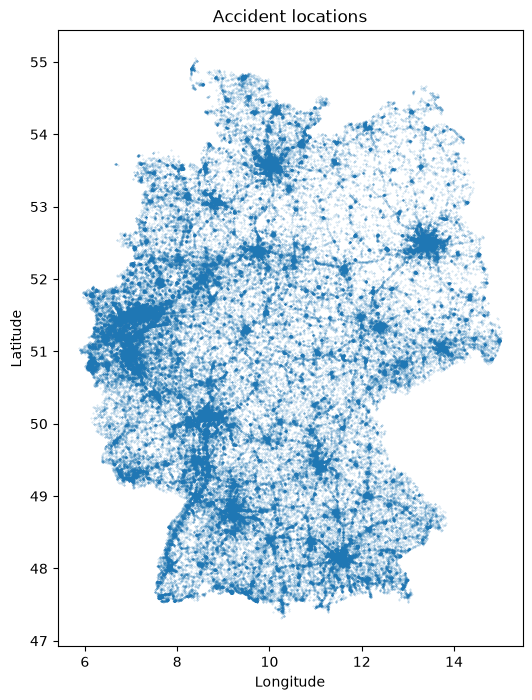

In [8]:
plt.figure(figsize=(6, 8))
plt.scatter(acc["longitude"], acc["latitude"], s=0.1, alpha=0.3)
plt.title("Accident locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

### Duplicates
Check if any accident appears more than once, as a full row or by its ID.

In [10]:
print("Duplicate rows:", acc.duplicated().sum())
print("Duplicate accident IDs:", acc["accident_id"].duplicated().sum())

Duplicate rows: 0
Duplicate accident IDs: 0


**Result:** 0 duplicate rows and 0 duplicate IDs. Every accident appears exactly once.

In [12]:
acc.columns

Index(['accident_id', 'state', 'region', 'district', 'municipality', 'year',
       'month', 'hour', 'weekday', 'severity', 'accident_kind',
       'accident_type', 'light', 'road_condition', 'bicycle', 'car',
       'pedestrian', 'motorcycle', 'truck', 'other_vehicle', 'utm_x', 'utm_y',
       'longitude', 'latitude', 'location_check', 'severe'],
      dtype='str')

In [13]:
acc["state"].describe()

count    273007.000000
mean          7.380708
std           3.639742
min           1.000000
25%           5.000000
50%           7.000000
75%           9.000000
max          16.000000
Name: state, dtype: float64

In [15]:
acc_state_names = {
    1: "Schleswig-Holstein", 2: "Hamburg", 3: "Niedersachsen", 4: "Bremen",
    5: "Nordrhein-Westfalen", 6: "Hessen", 7: "Rheinland-Pfalz", 8: "Baden-Württemberg",
    9: "Bayern", 10: "Saarland", 11: "Berlin", 12: "Brandenburg",
    13: "Mecklenburg-Vorpommern", 14: "Sachsen", 15: "Sachsen-Anhalt", 16: "Thüringen",
}
acc["state_name"] = acc["state"].map(acc_state_names)
acc["state_name"].value_counts()

state_name
Nordrhein-Westfalen       61521
Bayern                    46938
Baden-Württemberg         32042
Niedersachsen             24556
Hessen                    18578
Berlin                    13280
Rheinland-Pfalz           12816
Sachsen                   12724
Schleswig-Holstein        11645
Brandenburg                8459
Sachsen-Anhalt             7320
Hamburg                    7057
Thüringen                  5435
Mecklenburg-Vorpommern     4867
Saarland                   3194
Bremen                     2575
Name: count, dtype: int64

**Result:** All 16 states are included.
Nordrhein-Westfalen has the most accidents (61,521), followed by Bayern (46,938) and Baden-Württemberg (32,042).
Bremen has the fewest (2,575), followed by Saarland (3,194).
These are absolute numbers, so they don't show which state is more dangerous.

In [19]:
acc.head(5)

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name
0,01250509171013352025,1,0,60,7,2025,5,15,6,3,...,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein
1,01250405161013752025,1,0,62,53,2025,4,14,7,3,...,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein
2,01250118171013142025,1,0,56,15,2025,1,9,7,3,...,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein
3,01250326152013912025,1,0,55,28,2025,3,16,4,3,...,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein
4,01250225145013362025,1,0,58,116,2025,2,17,3,3,...,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein


In [ ]:
#acc["accident_id"].info()
#acc["state"].info()
#acc["region"].info()
#acc["region"].describe()
#acc.groupby("state_name")["region"].unique()
#acc[""].info()

<class 'pandas.Series'>
RangeIndex: 273007 entries, 0 to 273006
Series name: region
Non-Null Count   Dtype
--------------   -----
273007 non-null  int64
dtypes: int64(1)
memory usage: 2.1 MB


state_name
Baden-Württemberg                  [4, 2, 1, 3]
Bayern                    [6, 1, 5, 4, 7, 2, 3]
Berlin                                      [0]
Brandenburg                                 [0]
Bremen                                      [0]
Hamburg                   [1, 3, 7, 2, 6, 4, 5]
Hessen                                [4, 6, 5]
Mecklenburg-Vorpommern                      [0]
Niedersachsen                      [1, 4, 3, 2]
Nordrhein-Westfalen             [1, 5, 9, 7, 3]
Rheinland-Pfalz                       [3, 1, 2]
Saarland                                    [0]
Sachsen                               [5, 7, 6]
Sachsen-Anhalt                              [0]
Schleswig-Holstein                          [0]
Thüringen                                   [0]
Name: region, dtype: object

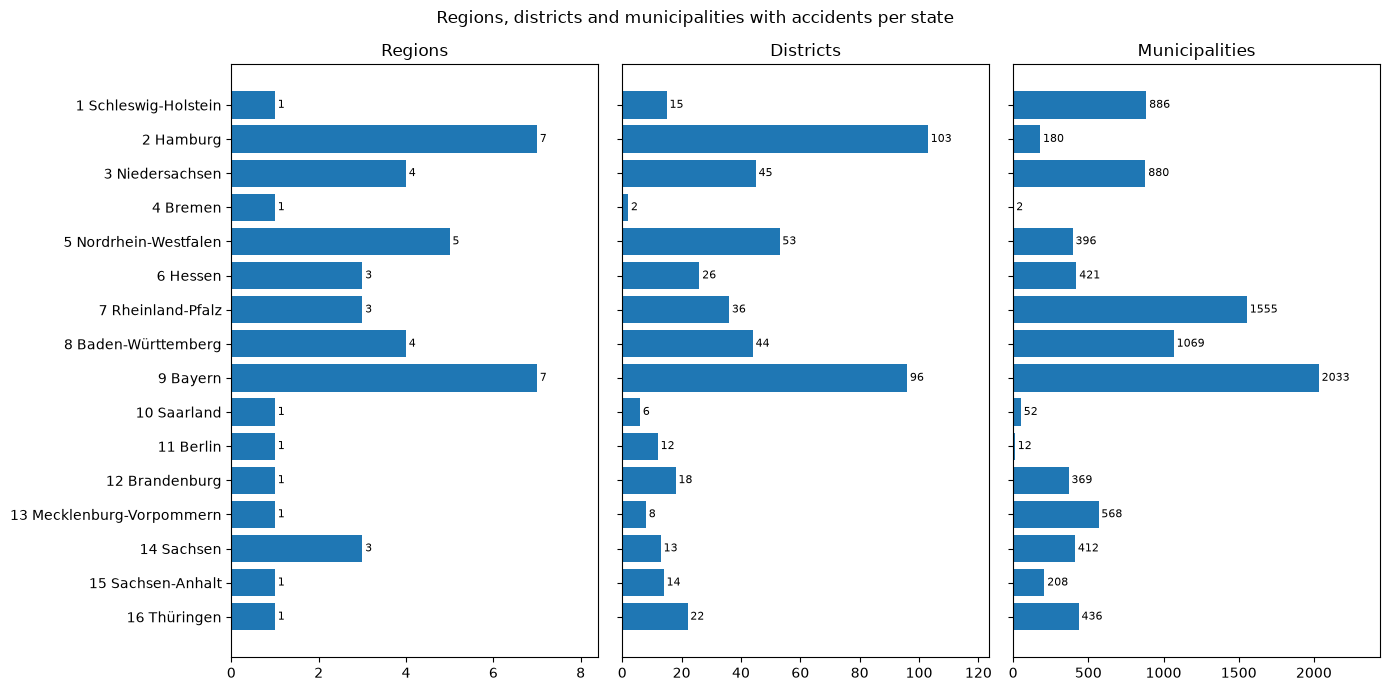

In [30]:
acc_levels_plot = acc_levels.copy()
acc_levels_plot.index = [f"{s} {n}" for s, n in acc_levels_plot.index]

acc_fig, acc_axes = plt.subplots(1, 3, figsize=(14, 7), sharey=True)
for acc_axis, acc_level in zip(acc_axes, ["regions", "districts", "municipalities"]):
    acc_bars = acc_axis.barh(acc_levels_plot.index, acc_levels_plot[acc_level])
    acc_axis.bar_label(acc_bars, fontsize=8, padding=2)
    acc_axis.set_title(acc_level.capitalize())
    acc_axis.margins(x=0.2)

acc_axes[0].invert_yaxis()
acc_fig.suptitle("Regions, districts and municipalities with accidents per state")
plt.tight_layout()
plt.show()

In [32]:
acc_k = acc.copy()

acc_k_reg = acc_k["state"].astype(str) + "-" + acc_k["region"].astype(str)
acc_k_dis = acc_k_reg + "-" + acc_k["district"].astype(str)
acc_k_mun = acc_k_dis + "-" + acc_k["municipality"].astype(str)

acc_k["region"] = acc_k_reg
acc_k["district"] = acc_k_dis
acc_k["municipality"] = acc_k_mun

acc_k[["state_name", "region", "district", "municipality"]].head()

,state_name,region,district,municipality
0,Schleswig-Holstein,1-0,1-0-60,1-0-60-7
1,Schleswig-Holstein,1-0,1-0-62,1-0-62-53
2,Schleswig-Holstein,1-0,1-0-56,1-0-56-15
3,Schleswig-Holstein,1-0,1-0-55,1-0-55-28
4,Schleswig-Holstein,1-0,1-0-58,1-0-58-116


In [34]:
print("Regions:", acc_k["region"].nunique(), "| plot sum:", acc_levels["regions"].sum())
print("Districts:", acc_k["district"].nunique(), "| plot sum:", acc_levels["districts"].sum())
print("Municipalities:", acc_k["municipality"].nunique(), "| plot sum:", acc_levels["municipalities"].sum())

Regions: 44 | plot sum: 44
Districts: 513 | plot sum: 513
Municipalities: 9479 | plot sum: 9479


In [35]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,motorcycle,truck,other_vehicle,utm_x,utm_y,longitude,latitude,location_check,severe,state_name
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,6,3,...,0,0,0,578658.6459,5.975442e+06,10.197759,53.921403,1,0,Schleswig-Holstein
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,7,3,...,0,0,0,577747.0359,5.933251e+06,10.173275,53.542399,1,0,Schleswig-Holstein
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,7,3,...,0,0,0,543500.2814,5.955820e+06,9.659670,53.749197,1,0,Schleswig-Holstein
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,4,3,...,0,0,0,601362.0656,6.003469e+06,10.552708,54.169272,1,0,Schleswig-Holstein
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,3,3,...,0,0,0,565151.5561,6.035316e+06,10.005090,54.461326,1,0,Schleswig-Holstein


### New dataset `acc_k` with combined location keys
`acc_k` is a copy of `acc`. The columns region, district and municipality were changed,
because their original codes repeat across states (e.g. district 22 exists in several states).

Each value now contains its full path, separated by dashes:
**state → region → district → municipality**

| Column | Before | After | Meaning |
|---|---|---|---|
| region | 0 | `1-0` | state 1, region 0 |
| district | 60 | `1-0-60` | state 1, region 0, district 60 |
| municipality | 7 | `1-0-60-7` | state 1, region 0, district 60, municipality 7 |

**Check:** the number of unique keys matches the counts per state from the plot
(44 regions, 513 districts, 9,479 municipalities), so every key is unique.

In [37]:
acc_k.info()

<class 'pandas.DataFrame'>
RangeIndex: 273007 entries, 0 to 273006
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   accident_id     273007 non-null  object 
 1   state           273007 non-null  int64  
 2   region          273007 non-null  str    
 3   district        273007 non-null  str    
 4   municipality    273007 non-null  str    
 5   year            273007 non-null  int64  
 6   month           273007 non-null  int64  
 7   hour            273007 non-null  int64  
 8   weekday         273007 non-null  int64  
 9   severity        273007 non-null  int64  
 10  accident_kind   273007 non-null  int64  
 11  accident_type   273007 non-null  int64  
 12  light           273007 non-null  int64  
 13  road_condition  273007 non-null  int64  
 14  bicycle         273007 non-null  int64  
 15  car             273007 non-null  int64  
 16  pedestrian      273007 non-null  int64  
 17  motorcycle      27300

In [39]:
acc_k["year_month"] = pd.to_datetime(acc_k["year"].astype(str) + "-" + acc_k["month"].astype(str), format="%Y-%m").dt.to_period("M")

acc_k[["year", "month", "year_month"]].head()

,year,month,year_month
0,2025,5,2025-05
1,2025,4,2025-04
2,2025,1,2025-01
3,2025,3,2025-03
4,2025,2,2025-02


In [56]:
acc_k.columns
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,latitude,location_check,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,53.921403,1,0,Schleswig-Holstein,2025-05,car,1,0,1,0
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,53.542399,1,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,53.749197,1,0,Schleswig-Holstein,2025-01,car,1,0,1,0
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,54.169272,1,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,54.461326,1,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0


In [41]:
acc_k["weekday"] = acc_k["weekday"].map({
    1: "Sunday", 2: "Monday", 3: "Tuesday", 4: "Wednesday",
    5: "Thursday", 6: "Friday", 7: "Saturday",
})
acc_k["weekday"] = pd.Categorical(acc_k["weekday"], categories=[
    "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday",
], ordered=True)

acc_k["weekday"].value_counts(sort=False)

weekday
Monday       41378
Tuesday      42829
Wednesday    41881
Thursday     43288
Friday       43932
Saturday     34174
Sunday       25525
Name: count, dtype: int64

In [44]:
acc_part = ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]

acc_k["participants"] = acc_k[acc_part].apply(lambda r: " + ".join(c for c in acc_part if r[c] == 1), axis=1)
acc_k["n_participant_types"] = acc_k[acc_part].sum(axis=1)

acc_k["participants"].value_counts().head(10)

participants
car                        92262
bicycle + car              43241
bicycle                    34334
car + motorcycle           19135
car + other_vehicle        19124
car + pedestrian           15501
motorcycle                 13375
other_vehicle               8118
car + truck                 7069
bicycle + other_vehicle     5558
Name: count, dtype: int64

In [47]:
acc_k["vulnerable"] = ((acc_k["bicycle"] == 1) | (acc_k["pedestrian"] == 1) | (acc_k["motorcycle"] == 1)).astype(int)
acc_k["single_type"] = (acc_k["n_participant_types"] == 1).astype(int)
acc_k["vulnerable_vs_vehicle"] = ((acc_k["vulnerable"] == 1) & ((acc_k["car"] == 1) | (acc_k["truck"] == 1) | (acc_k["other_vehicle"] == 1))).astype(int)

acc_k[["vulnerable", "single_type", "vulnerable_vs_vehicle"]].sum()

vulnerable               144353
single_type              149064
vulnerable_vs_vehicle     90995
dtype: int64

### New participant features
The six participant columns (bicycle, car, pedestrian, motorcycle, truck, other_vehicle) show who was involved.
One accident can involve several types, so new columns were created to describe the combinations:

| Column | Description |
|---|---|
| participants | All involved types as text, e.g. `bicycle + car` |
| n_participant_types | Number of different participant types involved (not number of people) |
| vulnerable | 1 = a bicycle, pedestrian or motorcycle was involved (road users without protection) |
| single_type | 1 = only one participant type was involved (e.g. a cyclist falling alone) |
| vulnerable_vs_vehicle | 1 = a vulnerable road user **and** a car, truck or other vehicle were involved |

**Limitation:** if more than two types are involved, the data does not show who collided with whom.

In [50]:
for acc_c in ["hour", "severity", "accident_kind", "accident_type", "light", "road_condition"]:
    print(acc_c, sorted(acc_k[acc_c].unique()))

hour [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]
severity [np.int64(1), np.int64(2), np.int64(3)]
accident_kind [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
accident_type [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7)]
light [np.int64(0), np.int64(1), np.int64(2)]
road_condition [np.int64(0), np.int64(1), np.int64(2)]


In [51]:
acc_k["severity"] = acc_k["severity"].map({
    1: "Accident with persons killed",
    2: "Accident with seriously injured",
    3: "Accident with slightly injured",
})
acc_k["accident_kind"] = acc_k["accident_kind"].map({
    0: "Accident of another kind",
    1: "Collision with another vehicle which starts, stops or is stationary",
    2: "Collision with another vehicle moving ahead or waiting",
    3: "Collision with another vehicle moving laterally in the same direction",
    4: "Collision with another oncoming vehicle",
    5: "Collision with another vehicle which turns into or crosses a road",
    6: "Collision between vehicle and pedestrian",
    7: "Collision with an obstacle in the carriageway",
    8: "Leaving the carriageway to the right",
    9: "Leaving the carriageway to the left",
})
acc_k["accident_type"] = acc_k["accident_type"].map({
    1: "Driving accident",
    2: "Accident caused by turning off the road",
    3: "Accident caused by turning into a road or by crossing it",
    4: "Accident caused by crossing the road",
    5: "Accident involving stationary",
    6: "Accident between vehicles moving along in carriageway",
    7: "Other accident",
})
acc_k["light"] = acc_k["light"].map({0: "daylight", 1: "twilight", 2: "darkness"})
acc_k["road_condition"] = acc_k["road_condition"].map({0: "dry", 1: "wet/damp/slippery", 2: "slippery (winter)"})

acc_k[["severity", "accident_kind", "accident_type", "light", "road_condition"]].isna().sum()

severity          0
accident_kind     0
accident_type     0
light             0
road_condition    0
dtype: int64

In [71]:
acc_k["accident_id"].map(type).value_counts()

accident_id
<class 'str'>    273007
Name: count, dtype: int64

In [72]:
acc_k["accident_id"] = acc_k["accident_id"].astype(str).str.zfill(20)

acc_id_month = acc_k["accident_id"].str[4:6].astype(int)
acc_id_day = acc_k["accident_id"].str[6:8].astype(int)

print("ID lengths:", acc_k["accident_id"].str.len().unique())
print("ID month values:", sorted(acc_id_month.unique()))
print("ID day values:", sorted(acc_id_day.unique()))
print("ID month differs from month column:", (acc_id_month != acc_k["month"]).sum())

ID lengths: [20]
ID month values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]
ID day values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(31)]
ID month differs from month column: 10


In [83]:
acc_k[acc_id_month != acc_k["month"]][["accident_id", "state_name", "month", "weekday", "hour"]]

,accident_id,state_name,month,weekday,hour
97803,09250113005111028820,Bayern,2,Thursday,9
99687,09250117003119062870,Bayern,2,Monday,11
100346,09250310006309092460,Bayern,4,Thursday,22
103635,09250412006102136950,Bayern,5,Monday,15
104516,09250425001170144840,Bayern,5,Sunday,21
107210,09250528005509256820,Bayern,6,Saturday,16
118642,09251019001409494090,Bayern,11,Wednesday,10
215688,09250221004105092400,Bayern,3,Friday,21
221369,09250519005515319100,Bayern,6,Thursday,21
225116,09250629005533263540,Bayern,7,Tuesday,14


### Finding: the accident ID contains the date
The data description does not document the structure of `accident_id`, but checking all rows shows:

**ID structure (20 characters):** 2-digit state + `25` (year) + 2-digit month + 2-digit day + further digits
Example: `01250509171013352025` → state 01, year 2025, month 05, day 09

**Loading problem:** 17,128 IDs (Schleswig-Holstein, Hamburg, Niedersachsen) were read as numbers,
so their leading zero was lost (19 instead of 20 characters). This was fixed with `zfill(20)`.

**Checks on all 273,007 IDs:**
- All IDs have 20 characters
- Month part contains only 1–12, day part only 1–31
- The ID month matches the `month` column in all rows except **10**

**The 10 mismatches:** all from **Bayern**, and in every case the `month` column is exactly one month
later than the ID month. Combining the ID **day** with the `month` column gives a date whose weekday
matches the `weekday` column in all 10 rows. So the `month` and `weekday` columns are consistent,
and the ID month is off by one in these rows.

**New column `date`:** built from `year`, the `month` column and the **day from the ID**.
Weekday check of the new date against the `weekday` column: ___ mismatches

In [82]:
acc_k["date"] = pd.to_datetime(dict(year=acc_k["year"], month=acc_k["month"], day=acc_id_day))

print("Weekday mismatch:", (acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str)).sum())
acc_k[["accident_id", "month", "weekday", "date"]].head()

Weekday mismatch: 8


,accident_id,month,weekday,date
0,01250509171013352025,5,Friday,2025-05-09
1,01250405161013752025,4,Saturday,2025-04-05
2,01250118171013142025,1,Saturday,2025-01-18
3,01250326152013912025,3,Wednesday,2025-03-26
4,01250225145013362025,2,Tuesday,2025-02-25


In [75]:
acc_k.head(10)

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,id_date_valid,date
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-05,car,1,0,1,0,True,2025-05-09
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,True,2025-04-05
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,car,1,0,1,0,True,2025-01-18
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,True,2025-03-26
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,True,2025-02-25
5,01250214145013972025,1,1-0,1-0-58,1-0-58-135,2025,2,10,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,car,1,0,1,0,True,2025-02-14
6,01250213161013652025,1,1-0,1-0-53,1-0-53-41,2025,2,11,Thursday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle + car,2,1,0,1,True,2025-02-13
7,01250520171013162025,1,1-0,1-0-60,1-0-60-2,2025,5,16,Tuesday,Accident with seriously injured,...,1,Schleswig-Holstein,2025-05,car + other_vehicle,2,0,0,0,True,2025-05-20
8,01250120125013112025,1,1-0,1-0-1,1-0-1-0,2025,1,15,Monday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,bicycle,1,1,1,0,True,2025-01-20
9,01250201105132612025,1,1-0,1-0-55,1-0-55-4,2025,2,15,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,car,1,0,1,0,True,2025-02-01


In [76]:
acc_k = acc_k.drop(columns=["id_date_valid"])

print("Weekday mismatch:", (acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str)).sum())

Weekday mismatch: 8


In [77]:
acc_wd = acc_k[acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str)].copy()
acc_wd["date_weekday"] = acc_wd["date"].dt.day_name()
acc_wd[["accident_id", "state_name", "date", "date_weekday", "weekday", "hour"]]

,accident_id,state_name,date,date_weekday,weekday,hour
105094,09250421004109128620,Bayern,2025-04-21,Monday,Saturday,15
110686,09250705003219291490,Bayern,2025-07-05,Saturday,Sunday,2
117122,09251025004109540040,Bayern,2025-10-25,Saturday,Friday,22
216339,09250126002219028530,Bayern,2025-01-26,Sunday,Wednesday,6
216359,09250129008571022830,Bayern,2025-01-29,Wednesday,Tuesday,7
226068,09250703008523271550,Bayern,2025-07-03,Thursday,Wednesday,10
227261,09250715008512385640,Bayern,2025-07-15,Tuesday,Sunday,17
252545,13250222314300690225,Mecklenburg-Vorpommern,2025-02-22,Saturday,Sunday,4


Weekday check: 8 rows (7 Bayern, 1 Mecklenburg-Vorpommern) have a date whose weekday does not match the weekday column, with no consistent pattern. Their date was set to missing; all other 272,999 dates are verified.

In [78]:
acc_k.loc[acc_wd.index, "date"] = pd.NaT

print("Missing dates:", acc_k["date"].isna().sum())
print("Weekday mismatch:", (acc_k["date"].dt.day_name() != acc_k["weekday"].astype(str))[acc_k["date"].notna()].sum())

Missing dates: 8
Weekday mismatch: 0


In [85]:
acc_k["date_check"] = "ok"
acc_k.loc[acc_id_month != acc_k["month"], "date_check"] = "month corrected"
acc_k.loc[acc_wd.index, "date_check"] = "date missing"

acc_k["date_check"].value_counts()

date_check
ok                 272989
month corrected        10
date missing            8
Name: count, dtype: int64

### Finding: the accident ID contains the date
The data description does not document the structure of `accident_id`, but checking all rows shows:

**ID structure (20 characters):** 2-digit state + `25` (year) + 2-digit month + 2-digit day + further digits
Example: `01250509171013352025` → state 01, year 2025, month 05, day 09

**Loading problem:** 17,128 IDs (Schleswig-Holstein, Hamburg, Niedersachsen) were read as numbers,
so their leading zero was lost (19 instead of 20 characters). This was fixed with `zfill(20)`.

**Checks on all 273,007 IDs:**
- All IDs have 20 characters
- Month part contains only 1–12, day part only 1–31
- The ID month matches the `month` column in all rows except 10

**New column `date`:** built from `year`, the `month` column and the **day from the ID**,
then checked against the `weekday` column.

**New column `date_check`:**

| Status | Rows | Meaning |
|---|---|---|
| ok | 272,989 | Date from the ID matches month and weekday |
| month corrected | 10 | ID month was one month too early (all Bayern); month taken from the `month` column, the weekday then matches |
| date missing | 8 | Weekday contradicts the date with no consistent pattern (7 Bayern, 1 Mecklenburg-Vorpommern); date set to missing |

These 18 rows are data inconsistencies, not outliers. They are kept, because all other columns are still valid.

In [86]:
acc_k.loc[acc_k["date_check"] != "ok", "date"] = pd.NaT
acc_k.loc[acc_k["date_check"] == "month corrected", "date_check"] = "date missing (month mismatch)"
acc_k.loc[acc_k["date_check"] == "date missing", "date_check"] = "date missing (weekday mismatch)"

print("Missing dates:", acc_k["date"].isna().sum())
acc_k["date_check"].value_counts()

Missing dates: 18


date_check
ok                                 272989
date missing (month mismatch)          10
date missing (weekday mismatch)         8
Name: count, dtype: int64

| Status | Rows | Meaning |
|---|---|---|
| ok | 272,989 | Date from the ID matches month and weekday |
| date missing (month mismatch) | 10 | ID month contradicts the `month` column (all Bayern) |
| date missing (weekday mismatch) | 8 | ID day contradicts the `weekday` column (7 Bayern, 1 Mecklenburg-Vorpommern) |

The date of these 18 rows was set to missing instead of guessed. The rows are kept, because all other columns are still valid.

In [89]:
acc_k[acc_k["date"].isna()][["accident_id", "date", "date_check"]]

,accident_id,date,date_check
97803,09250113005111028820,NaT,date missing (month mismatch)
99687,09250117003119062870,NaT,date missing (month mismatch)
100346,09250310006309092460,NaT,date missing (month mismatch)
103635,09250412006102136950,NaT,date missing (month mismatch)
104516,09250425001170144840,NaT,date missing (month mismatch)
105094,09250421004109128620,NaT,date missing (weekday mismatch)
107210,09250528005509256820,NaT,date missing (month mismatch)
110686,09250705003219291490,NaT,date missing (weekday mismatch)
117122,09251025004109540040,NaT,date missing (weekday mismatch)
118642,09251019001409494090,NaT,date missing (month mismatch)


In [90]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok


In [91]:
for acc_c in ["bicycle", "car", "pedestrian", "motorcycle", "truck", "other_vehicle"]:
    print(acc_c, sorted(acc_k[acc_c].unique()))

bicycle [np.int64(0), np.int64(1)]
car [np.int64(0), np.int64(1)]
pedestrian [np.int64(0), np.int64(1)]
motorcycle [np.int64(0), np.int64(1)]
truck [np.int64(0), np.int64(1)]
other_vehicle [np.int64(0), np.int64(1)]


### Check of `location_check`
`location_check` (original: PLST) shows how the location of each accident was verified by the statistical offices
(source: official data description):
- **1** = successful location check according to the regular procedure
- **2** = successful location check according to an advanced procedure for accidents involving bicycles

**What is checked:**
1. The column contains only the values 1 and 2.
2. Level 2 only appears in accidents with a bicycle involved (`bicycle = 1`), otherwise the two columns contradict each other.

The column describes the verification of the location, not the accident itself, so it is not used as a feature for the model.

In [92]:
print(acc_k["location_check"].value_counts())
print("Check 2 without bicycle:", ((acc_k["location_check"] == 2) & (acc_k["bicycle"] == 0)).sum())

location_check
1    265616
2      7391
Name: count, dtype: int64
Check 2 without bicycle: 0


**Result:** Only the values 1 (265,616 accidents) and 2 (7,391 accidents) appear.
All 7,391 accidents with level 2 involve a bicycle, so the column is consistent with `bicycle`.

In [93]:
acc_k.head()

,accident_id,state,region,district,municipality,year,month,hour,weekday,severity,...,severe,state_name,year_month,participants,n_participant_types,vulnerable,single_type,vulnerable_vs_vehicle,date,date_check
0,01250509171013352025,1,1-0,1-0-60,1-0-60-7,2025,5,15,Friday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-05,car,1,0,1,0,2025-05-09,ok
1,01250405161013752025,1,1-0,1-0-62,1-0-62-53,2025,4,14,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-04,bicycle,1,1,1,0,2025-04-05,ok
2,01250118171013142025,1,1-0,1-0-56,1-0-56-15,2025,1,9,Saturday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-01,car,1,0,1,0,2025-01-18,ok
3,01250326152013912025,1,1-0,1-0-55,1-0-55-28,2025,3,16,Wednesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-03,car + pedestrian,2,1,0,1,2025-03-26,ok
4,01250225145013362025,1,1-0,1-0-58,1-0-58-116,2025,2,17,Tuesday,Accident with slightly injured,...,0,Schleswig-Holstein,2025-02,bicycle,1,1,1,0,2025-02-25,ok


## Final dataset `acc_k`
**273,007 accidents, 35 columns.** All original columns were renamed, checked against the official
data description, and codes were replaced by their official names.

| Group | Columns |
|---|---|
| ID | accident_id (20 characters, leading zeros restored) |
| Location (keys) | state, state_name, region, district, municipality (e.g. `1-0-60-7`) |
| Coordinates | utm_x, utm_y, longitude, latitude |
| Time | year, month, hour, weekday, year_month, date, date_check |
| Accident | severity, accident_kind, accident_type |
| Conditions | light, road_condition |
| Participants | bicycle, car, pedestrian, motorcycle, truck, other_vehicle |
| New participant features | participants, n_participant_types, vulnerable, single_type, vulnerable_vs_vehicle |
| Target | severe (1 = killed or seriously injured, 0 = slightly injured) |
| Location verification | location_check |

**Data quality:** no duplicates, no missing values except 18 dates set to missing (see `date_check`).

In [94]:
acc_sev = acc_k["severity"].value_counts().to_frame("count")
acc_sev["percent"] = (acc_sev["count"] / len(acc_k) * 100).round(1)
acc_sev

,count,percent
severity,,
Accident with slightly injured,230100,84.3
Accident with seriously injured,40430,14.8
Accident with persons killed,2477,0.9


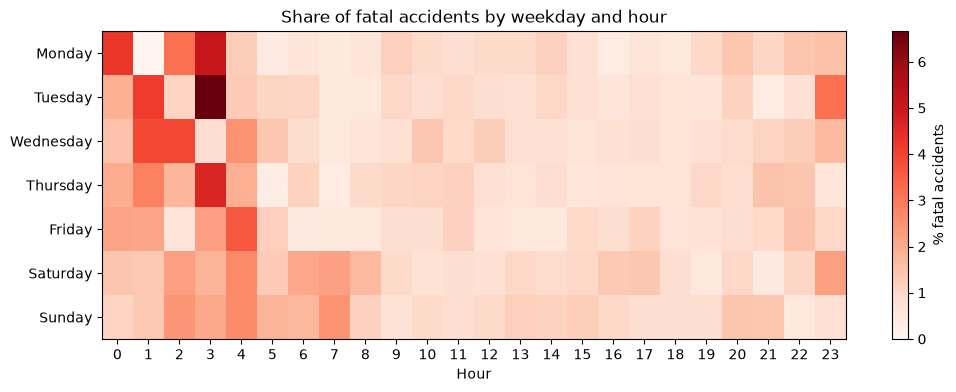

In [95]:
acc_k["killed"] = (acc_k["severity"] == "Accident with persons killed").astype(int)
acc_heat = acc_k.pivot_table(index="weekday", columns="hour", values="killed", aggfunc="mean", observed=True)

plt.figure(figsize=(12, 4))
plt.imshow(acc_heat * 100, aspect="auto", cmap="Reds")
plt.colorbar(label="% fatal accidents")
plt.yticks(range(7), acc_heat.index)
plt.xticks(range(24), acc_heat.columns)
plt.xlabel("Hour")
plt.title("Share of fatal accidents by weekday and hour")
plt.show()

In [96]:
print(acc_k.describe(include="number").T)
acc_k.describe(exclude="number").T

                          count          mean            std           min  \
state                  273007.0  7.380708e+00       3.639742  1.000000e+00   
year                   273007.0  2.025000e+03       0.000000  2.025000e+03   
month                  273007.0  6.641009e+00       3.180641  1.000000e+00   
hour                   273007.0  1.343959e+01       4.780902  0.000000e+00   
bicycle                273007.0  3.279073e-01       0.469452  0.000000e+00   
car                    273007.0  7.237836e-01       0.447126  0.000000e+00   
pedestrian             273007.0  8.804536e-02       0.283361  0.000000e+00   
motorcycle             273007.0  1.344215e-01       0.341105  0.000000e+00   
truck                  273007.0  3.977554e-02       0.195432  0.000000e+00   
other_vehicle          273007.0  1.449487e-01       0.352050  0.000000e+00   
utm_x                  273007.0  5.491049e+05  151910.316367  2.804342e+05   
utm_y                  273007.0  5.636704e+06  197074.118960  5.

,count,unique,top,freq,mean,min,25%,50%,75%,max
accident_id,273007,273007,01250509171013352025,1,NaN,NaN,NaN,NaN,NaN,NaN
region,273007,44,5-1,18031,NaN,NaN,NaN,NaN,NaN,NaN
district,273007,513,9-1-62,5264,NaN,NaN,NaN,NaN,NaN,NaN
municipality,273007,9479,9-1-62-0,5264,NaN,NaN,NaN,NaN,NaN,NaN
weekday,273007,7,Friday,43932,NaN,NaN,NaN,NaN,NaN,NaN
severity,273007,3,Accident with slightly injured,230100,NaN,NaN,NaN,NaN,NaN,NaN
accident_kind,273007,10,Collision with another vehicle which turns int...,72677,NaN,NaN,NaN,NaN,NaN,NaN
accident_type,273007,7,Accident between vehicles moving along in carr...,64220,NaN,NaN,NaN,NaN,NaN,NaN
light,273007,3,daylight,208489,NaN,NaN,NaN,NaN,NaN,NaN
road_condition,273007,3,dry,212665,NaN,NaN,NaN,NaN,NaN,NaN


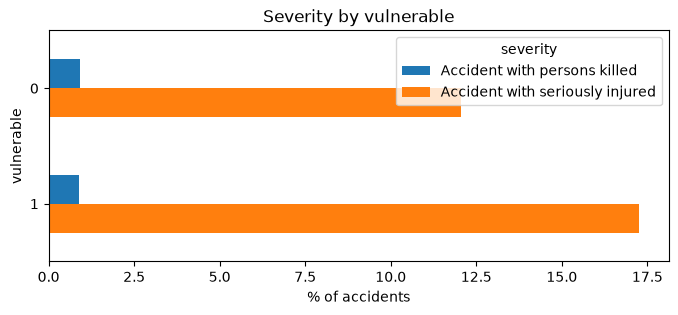

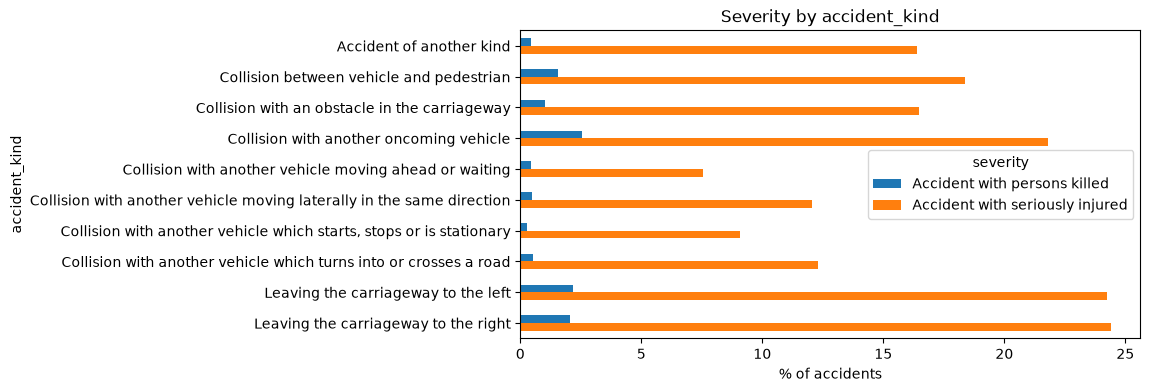

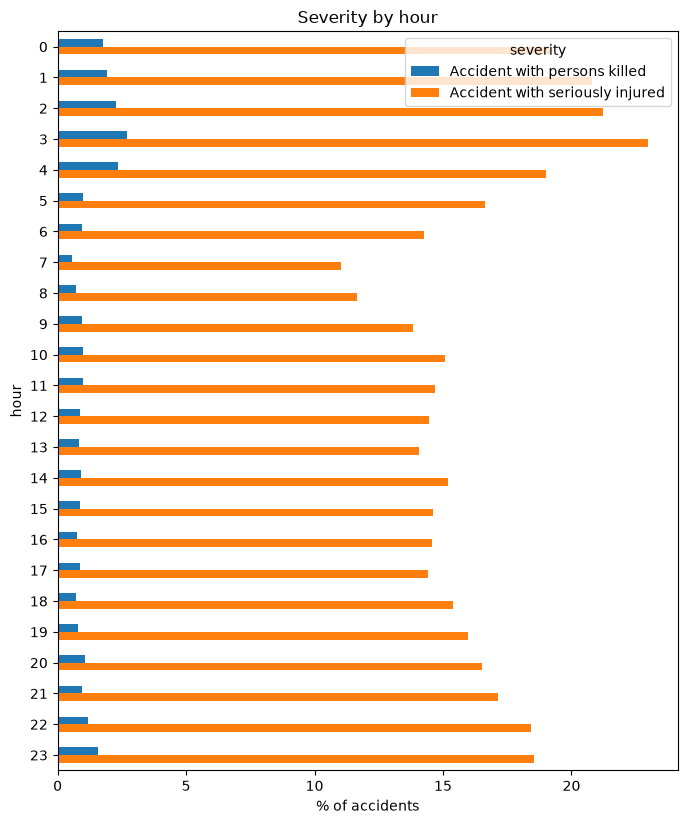

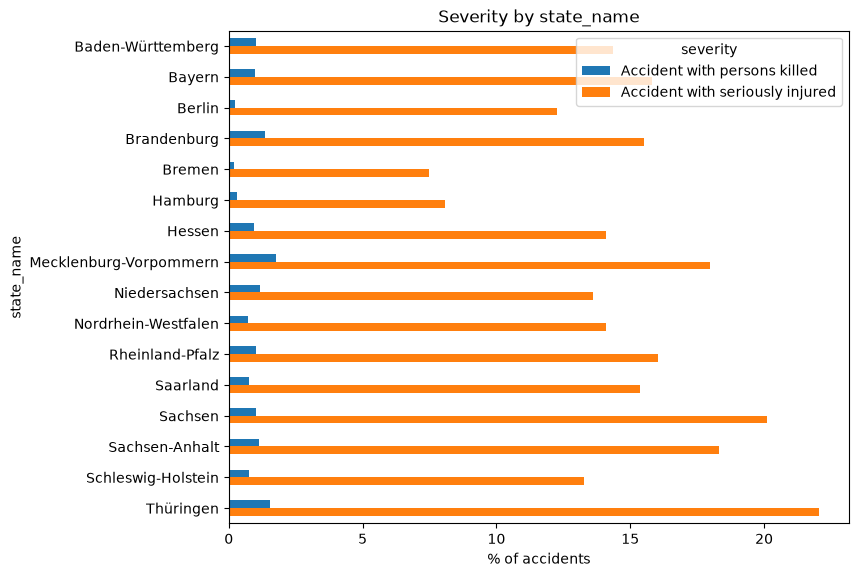

In [97]:
acc_sev_order = ["Accident with persons killed", "Accident with seriously injured", "Accident with slightly injured"]

def acc_sev_plot(acc_col):
    acc_tab = pd.crosstab(acc_k[acc_col], acc_k["severity"], normalize="index")[acc_sev_order] * 100
    acc_tab[acc_sev_order[:2]].plot(kind="barh", figsize=(8, max(3, len(acc_tab) * 0.4)))
    plt.title(f"Severity by {acc_col}")
    plt.xlabel("% of accidents")
    plt.gca().invert_yaxis()
    plt.show()

for acc_col in ["vulnerable", "accident_kind", "hour", "state_name"]:
    acc_sev_plot(acc_col)

In [98]:
acc_explore_cols = ["participants", "vulnerable", "vulnerable_vs_vehicle", "single_type",
                    "accident_kind", "accident_type", "light", "road_condition",
                    "hour", "weekday", "month", "state_name"]

acc_rows = []
for acc_col in acc_explore_cols:
    acc_grp = acc_k.groupby(acc_col, observed=True)["severity"]
    for acc_val, acc_s in acc_grp:
        if len(acc_s) >= 500:
            acc_rows.append({
                "column": acc_col, "value": acc_val, "accidents": len(acc_s),
                "% killed": round((acc_s == "Accident with persons killed").mean() * 100, 2),
                "% seriously": round((acc_s == "Accident with seriously injured").mean() * 100, 2),
            })

acc_results = pd.DataFrame(acc_rows).sort_values("% killed", ascending=False)
acc_results.head(15)

,column,value,accidents,% killed,% seriously
5,participants,bicycle + truck,787,4.07,24.90
17,participants,truck + other_vehicle,748,3.74,19.92
16,participants,truck,975,3.18,23.79
50,hour,3,1288,2.72,22.98
10,participants,car + truck,7069,2.60,14.46
27,accident_kind,Collision with another oncoming vehicle,18985,2.54,21.81
51,hour,4,1395,2.37,19.00
49,hour,2,1498,2.27,21.23
15,participants,pedestrian + other_vehicle,3237,2.26,15.45
32,accident_kind,Leaving the carriageway to the left,12947,2.19,24.23


In [99]:
acc_results[acc_results["column"].isin(["road_condition", "light"])].sort_values(["column", "% killed"], ascending=[True, False])

,column,value,accidents,% killed,% seriously
41,light,darkness,50553,1.23,16.10
43,light,twilight,13965,0.84,14.52
42,light,daylight,208489,0.83,14.52
46,road_condition,wet/damp/slippery,54919,0.95,13.72
44,road_condition,dry,212665,0.90,15.12
45,road_condition,slippery (winter),5423,0.53,13.79
